Counter({1: 4, 2: 3, 5: 2, 0: 1, 3: 1})
[0, 1, 2, 3, 5]
[1, 4, 3, 1, 2]


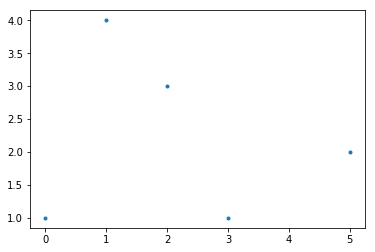

In [5]:
import matplotlib.pyplot as plt
import collections
a = [1,1,1,2,2,1,3,5,5,2,0]
counter = collections.Counter(a)
print(counter)

xdata = counter.keys()
ydata = counter.values()

print(xdata)
print(ydata)

plt.plot(xdata, ydata, '.')
plt.show()

In [1]:
import numpy as np

roi1 = np.genfromtxt('s2e3.csv', delimiter=',')
roi_list1 = roi1[:len(roi1),3]

roi2 = np.genfromtxt('s2e3.csv', delimiter=',')
roi_list2 = roi2[:len(roi2),3]

roi = np.append(roi_list1, roi_list2)
print len(roi)
print len(roi_list1)

3978
1989


In [2]:
a = np.absolute (roi_list1)
a

array([ 4.,  4.,  5., ...,  8.,  6.,  2.])

In [3]:
b = [2,3,4,5]

b = b/np.linalg.norm (b)
print b

c = 2*b

c = c/np.linalg.norm (c)
print c
print 2*a

[ 0.27216553  0.40824829  0.54433105  0.68041382]
[ 0.27216553  0.40824829  0.54433105  0.68041382]
[  8.   8.  10. ...,  16.  12.   4.]


In [4]:
a = [2,3,-4]
print np.std(a)
print np.var(a)
print np.std(a)**2


3.09120616517
9.55555555556
9.55555555556


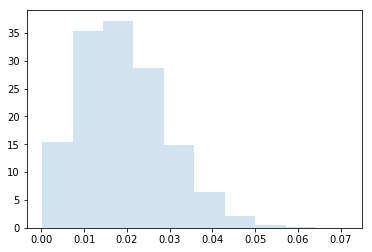

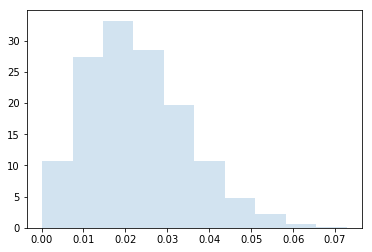

In [5]:
from scipy.stats import rayleigh
import numpy as np
import matplotlib.pyplot as plt

b = 20

#Generate random numbers:
r = rayleigh.rvs(loc = 0, scale = 0.0151180007303, size=8000)
r2 = rayleigh.rvs(loc = 0, scale = 0.0183011134495, size=8000)

#And compare the histogram:
plt.hist(r, normed=True, histtype='stepfilled', alpha=0.2)
plt.show()
plt.hist(r2, normed=True, histtype='stepfilled', alpha=0.2)
plt.show()

In [6]:
import numpy as np
import scipy.special as sc
import matplotlib.pyplot as plt

x = 0.6
print sc.assoc_laguerre(x,0.5,0)

0.675019919573


In [7]:
import numpy as np
import scipy.optimize as opt

def main():
    nobservations = 4
    a, b, c = 3.0, 2.0, 1.0
    f, x, y, z = generate_data(nobservations, a, b, c)

    print 'Linear results (should be {}, {}, {}):'.format(a, b, c)
    print linear_invert(f, x, y, z)

    print 'Non-linear results (should be {}, {}, {}):'.format(a, b, c)
    print nonlinear_invert(f, x, y, z)

def generate_data(nobservations, a, b, c, noise_level=0.01):
    x, y, z = np.random.random((3, nobservations))
    noise = noise_level * np.random.normal(0, noise_level, nobservations)
    f = func(x, y, z, a, b, c) + noise
    return f, x, y, z

def func(x, y, z, a, b, c):
    f = (a**2
         + x * b**2
         + y * a * b * np.cos(c)
         + z * a * b * np.sin(c))
    return f

def linear_invert(f, x, y, z):
    G = np.vstack([np.ones_like(x), x, y, z]).T
    m, _, _, _ = np.linalg.lstsq(G, f)

    d, e, f, g = m
    a = np.sqrt(d)
    b = np.sqrt(e)
    c = np.arctan2(g, f) # Note that `c` will be in radians, not degrees
    return a, b, c

def nonlinear_invert(f, x, y, z):
    # "curve_fit" expects the function to take a slightly different form...
    def wrapped_func(observation_points, a, b, c):
        x, y, z = observation_points
        return func(x, y, z, a, b, c)

    xdata = np.vstack([x, y, z])
    model, cov = opt.curve_fit(wrapped_func, xdata, f)
    return model

main()

Linear results (should be 3.0, 2.0, 1.0):
(3.0008357182220329, 1.999755605929538, 1.0004172906579591)
Non-linear results (should be 3.0, 2.0, 1.0):
[ 2.99996842  2.00003613  0.99998337]


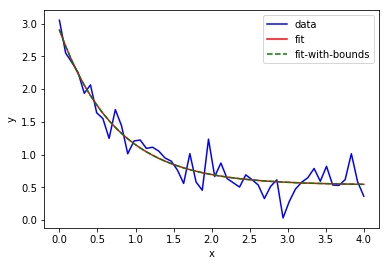

In [8]:
>>> import numpy as np
>>> import matplotlib.pyplot as plt
>>> from scipy.optimize import curve_fit
import scipy.optimize as sci


>>> def func(x, a, b, c):
...     return a * np.exp(-b * x) + c

>>> xdata = np.linspace(0, 4, 50)
>>> y = func(xdata, 2.5, 1.3, 0.5)
>>> y_noise = 0.2 * np.random.normal(size=xdata.size)
>>> ydata = y + y_noise
>>> plt.plot(xdata, ydata, 'b-', label='data')

>>> popt, pcov = curve_fit(func, xdata, ydata)
>>> plt.plot(xdata, func(xdata, *popt), 'r-', label='fit')

>>> popt, pcov = curve_fit(func, xdata, ydata, bounds=(0, [3., 2., 1.]))
>>> plt.plot(xdata, func(xdata, *popt), 'g--', label='fit-with-bounds')

>>> plt.xlabel('x')
>>> plt.ylabel('y')
>>> plt.legend()
>>> plt.show()

[  0.00000000e+00   2.87867172e-63   7.10731355e-63   1.45575062e-62
   2.83294061e-62   5.38919426e-62   1.01049460e-61   1.87403115e-61
   3.44468522e-61   6.28479566e-61   1.13942667e-60   2.05452266e-60
   3.68688448e-60   6.58818576e-60   1.17278187e-59   2.08049073e-59
   3.67905436e-59   6.48682193e-59   1.14061685e-58   2.00047405e-58
   3.50004711e-58   6.10965086e-58   1.06415995e-57   1.84963451e-57
   3.20840287e-57   5.55452711e-57   9.59816420e-57   1.65552890e-56
   2.85045942e-56   4.89939207e-56   8.40691261e-56   1.44017058e-55
   2.46313919e-55   4.20605391e-55   7.17106483e-55   1.22074917e-54
   2.07497720e-54   3.52171030e-54   5.96837228e-54   1.01001559e-53
   1.70677969e-53   2.88012185e-53   4.85327126e-53   8.16684742e-53
   1.37238498e-52   2.30305447e-52   3.85961488e-52   6.45951197e-52
   1.07963164e-51   1.80208631e-51   3.00402371e-51   5.00106371e-51
   8.31487943e-51   1.38066131e-50   2.28959625e-50   3.79204921e-50
   6.27241735e-50   1.03620177e-49

C:\Users\Yuri\Anaconda2\lib\site-packages\ipykernel\__main__.py:10: RuntimeWarning: invalid value encountered in multiply


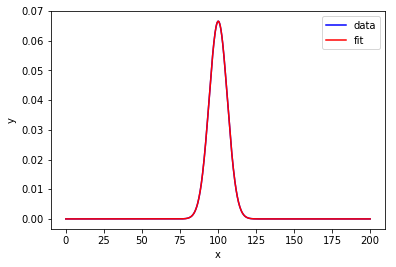

In [59]:
>>> import numpy as np
>>> import matplotlib.pyplot as plt
>>> from scipy.optimize import curve_fit
import scipy.special as sci

v = 100
s = 6

>>> def func(x, v, s):
    f = (x/s**2)*np.exp(-1*(x**2+v**2)/(2*s**2))*sci.iv(0,x*v/(s**2))
    return f

>>> xdata = np.linspace(0, 200, 1000)
>>> y = func(xdata, v, s)
print y
>>> ydata = y
>>> plt.plot(xdata, ydata, 'b-', label='data')

>>> popt, pcov = curve_fit(func, xdata, ydata)
>>> plt.plot(xdata, func(xdata, *popt), 'r-', label='fit')

print popt, np.sqrt(np.diag(pcov))

>>> plt.xlabel('x')
>>> plt.ylabel('y')
>>> plt.legend()
>>> plt.show()

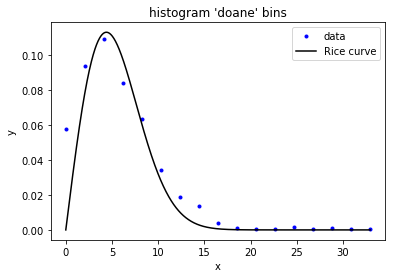

[-0.04427658  4.39628401  0.81984814] [  2.23533647e+05   1.12581560e+03   8.48936241e-02]
0.82469150475
Power_divergenceResult(statistic=inf, pvalue=0.0)


C:\Users\Yuri\Anaconda2\lib\site-packages\scipy\stats\stats.py:4351: RuntimeWarning: divide by zero encountered in true_divide
  terms = (f_obs - f_exp)**2 / f_exp


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import scipy.special as sci
from sklearn.metrics import r2_score
from scipy.stats import chisquare

#import csv file for ROI pixel list
def import_roi (roi_file):
    roi = np.genfromtxt(roi_file, delimiter=',')
    roi_intensities = roi[:len(roi),3] #deixa somente as intensidades
    return (roi_intensities)
#normalize list, Frobenius norm
def normalize_roi (roi_intensities):
    roi_normalized = roi_intensities/np.linalg.norm (roi_intensities)
    return (roi_normalized)


a = import_roi('s2e3.csv')
#a = normalize_roi(a)

[a_hist, a_bins] = np.histogram(a, bins='doane', density=True)

xdata = a_bins[0:len(a_bins)-1]
ydata = a_hist

def func(x, v, s, k):
    f = k*(x/s**2)*np.exp(-1*(x**2+v**2)/(2*s**2))*sci.iv(0,x*v/(s**2))
    return f

popt, pcov = curve_fit(func, xdata, ydata)

x_verif = np.linspace(0, xdata.max(), 1000)
y_verif = func(x_verif, popt[0], popt[1], popt[2])

plt.plot(xdata, ydata, 'b.', label='data')
#plt.hist(a, bins='doane')
plt.plot(x_verif, y_verif, 'k', label='Rice curve')

plt.title("histogram 'doane' bins")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

print popt, np.sqrt(np.diag(pcov))
#>>> popt, pcov = curve_fit(func, xdata, ydata, bounds=(0, [3., 2., 1.]))
#>>> plt.plot(xdata, func(xdata, *popt), 'g--', label='fit-with-bounds')

print r2_score(ydata, func(xdata, popt[0], popt[1], popt[2]))
print chisquare(ydata, func(xdata, popt[0], popt[1], popt[2]))

In [11]:
import numpy as np
import scipy.optimize as opt
from scipy.stats import rice
import matplotlib.pyplot as plt
def main():
    R = 2
    s = 1
    b = R/s

    mean, var = rice.stats(b, moments='mv')
    print mean
    print var

    dist = rice.rvs(b, size=10)
    print dist
    dist_mean = np.mean(dist)
    dist_var = np.var(dist)
    print dist_mean
    print dist_var

    nobservations = 1000

    print 'Non-linear results (should be {}, {}, {}):'.format(R, s, c)
    print nonlinear_invert(f, x, y, z)

def func(R, s):
    f = 2*(s**2)+R**2
    return f 
    
def nonlinear_invert(f, x, y, z):
    # "curve_fit" expects the function to take a slightly different form...
    def wrapped_func(observation_points, a, b, c):
        x, y, z = observation_points
        return func(x, y, z, a, b, c)

    xdata = np.vstack([x, y, z])
    model, cov = opt.curve_fit(wrapped_func, xdata, f)
    return model
main()

2.27238342807
0.836273555839
[ 1.39725025  2.59979008  2.84596643  1.73950136  1.36149745  2.33601262
  1.39187687  2.26793597  3.37027174  1.61684763]
2.0926950393
0.440729424136
Non-linear results (should be 2, 1, [ 0.27216553  0.40824829  0.54433105  0.68041382]):


NameError: global name 'f' is not defined

In [74]:
def import_roi (roi_file):
    roi = np.genfromtxt(roi_file, delimiter=',')
    roi_intensities = roi[:len(roi),3] #deixa somente as intensidades
    return (roi_intensities)
for i in range(1,20):
    a = import_roi('roi (%d).csv' % i)
    print a


[ nan   6.   8. ...,   1.   3.   6.]
[  nan  418.  422. ...,  495.  500.  499.]
[  nan  475.  480. ...,  472.  482.  478.]
[  nan  373.  370. ...,  358.  356.  356.]
[  nan  341.  346.  349.  347.  344.  344.  351.  359.  357.  344.  327.
  318.  319.  323.  323.  318.  315.  318.  323.  340.  344.  343.  336.
  331.  333.  339.  343.  345.  347.  350.  352.  351.  349.  345.  338.
  326.  316.  315.  321.  325.  321.  315.  316.  323.  330.  334.  337.
  336.  333.  330.  340.  344.  348.  351.  353.  350.  343.  334.  329.
  329.  334.  338.  340.  342.  347.  352.  352.  347.  340.  334.  328.
  321.  319.  320.  321.  319.  317.  320.  326.  330.  330.  329.  327.
  326.  326.  329.  330.  329.  327.  341.  349.  351.  345.  341.  349.
  362.  367.  358.  342.  330.  327.  330.  333.  333.  332.  332.  336.
  342.  350.  353.  347.  337.  329.  326.  326.  323.  316.  312.  315.
  322.  328.  327.  321.  315.  315.  319.  325.  329.  327.  321.  317.
  320.  328.  332.  355.  330. 

[ 0.00670206 -0.00117119] [  4.23390464e-05   3.44950112e-05]
[ 45.60672235  -7.96981004]


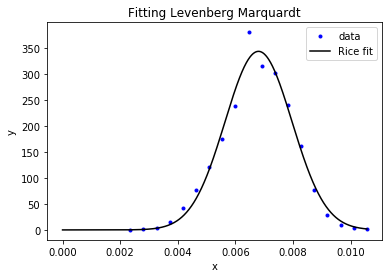

5.15927902859 0.000713293354045 0.00119119839159


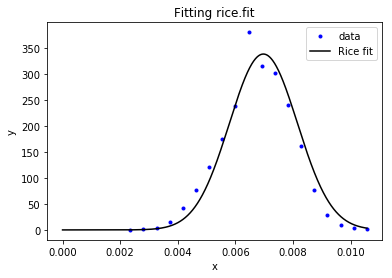

0.979807764761
Power_divergenceResult(statistic=44.120210755474389, pvalue=0.0005545133257124882)


In [92]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import scipy.special as sci
from sklearn.metrics import r2_score
from scipy.stats import chisquare, rice

#import csv file for ROI pixel list
def import_roi (roi_file):
    roi = np.genfromtxt(roi_file, delimiter=',')
    roi_intensities = roi[1:len(roi),3] #deixa somente as intensidades
    return (roi_intensities)
#normalize list, Frobenius norm
def normalize_roi (roi_intensities):
    roi_normalized = roi_intensities/np.linalg.norm (roi_intensities)
    return (roi_normalized, np.linalg.norm (roi_intensities))
#define pdf for Rice (probability distribution function)
def func(x, v, s):
    f = (x/s**2)*np.exp(-1*(x**2+v**2)/(2*s**2))*sci.iv(0,x*v/(s**2))
    return f

#for i in range(1,48):  #number of ROIs to be analyzed
#    print i
#a = import_roi('roi (%d).csv' % i)
a = import_roi('roi (10).csv')

#data prep
nbins = np.max(a)-np.min(a)
a,norm = normalize_roi(a)

#fitting levenberg Marquardt
#data prep
[a_hist, a_bins] = np.histogram(a, bins='doane', density=True)
xdata = a_bins[0:len(a_bins)-1]
ydata = a_hist
#fit
popt, pcov = curve_fit(func, xdata, ydata)
print popt, np.sqrt(np.diag(pcov))
print popt*norm
x_verif = np.linspace(0, xdata.max(), 1000)
y_verif = func(x_verif, popt[0], popt[1])
#plot
plt.plot(xdata, ydata, 'b.', label='data')
plt.plot(x_verif, y_verif, 'k', label='Rice fit')
plt.title("Fitting Levenberg Marquardt")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


#fitting rice.fit
#fit
shape, loc, scale = rice.fit(a)
print shape, loc, scale
y2_verif = rice.pdf(x_verif, shape, loc, scale)
#plot
fig, ax = plt.subplots(1, 1)
#ax.hist(y2_verif, normed=True, histtype='stepfilled', alpha=0.2)
#ax.hist(a, normed=True, histtype='stepfilled', alpha=0.2)
plt.plot(xdata, ydata, 'b.', label='data')
plt.plot(x_verif, y2_verif, 'k', label='Rice fit')
plt.title("Fitting rice.fit")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

#correlation stats
print r2_score(ydata, func(xdata, popt[0], popt[1]))
print chisquare(ydata, func(xdata, popt[0], popt[1]))

In [9]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib inline

#funções para incializar


def dixon(s23,s46):
    
    rw = (s46 + s23)/2
    rf = (s46 - s23)/2
         
    ff = rf / (rf + rw)
    
    return(ff)

magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
inicial = [0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05]
inicial = np.array(inicial)


def func_V8(x, a, b):
    return np.absolute(a*np.exp(-x/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*x) + 
                       b*np.exp(-x/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*x) + 
                       c*np.exp(-x/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*x) + 
                       d*np.exp(-x/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*x) + 
                       e*np.exp(-x/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*x) +
                       f*np.exp(-x/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*x) +
                       g*np.exp(-x/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*x))



bd = (0, [1., 1., 1., 1., 1., 1., 1.]) # Bounds
x = np.linspace(0,0.008,1001)



#valores de %FF: (inicial, final e numero de valores)
FF = np.linspace(0.1, 0.1, 1)
print FF
'''#para plotar somente os 7 pontos, use este t (em 3 Tesla)
t = [0.0011515,  \
0.0011515*2,\
0.0011515*3,\
0.0011515*4,\
0.0011515*5,\
0.0011515*6,\
0.0011515*7]
t = np.array(t)'''


#para plotar a curva toda
t = np.linspace(0, 0.008, 100)


# t2star = [0.030,\
# 0.040,\
# 0.051,\
# 0.052,\
# 0.062,\
# 0.083,\
# 0.023]
#t2star = np.array(t2star)

#frequencia relativa agua/gordura em ppm
Fppmn = [5.3,\
4.2,\
2.75,\
2.1,\
1.3,\
0.9,\
4.7]
Fppmn = np.array(Fppmn)

#calculo da frequencia relativa agua/gordura
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = [0,0,0,0,0,0,0]
freq = np.array(freq)
for n in range(0,len(Fppmn)):
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

#inicialização dos arrays que receberão os sinais (temporario e final)
S = (len(Fppmn),len(t)) #num. linhas: qtde de componentes; num. col: qtde de pontos t
S = np.zeros(S,dtype='complex')
Sfinal= (len(t))
Sfinal=np.zeros(Sfinal,dtype='complex')

for fatPercent in FF:

    rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water
    rho = np.array(rho)

    Sfinal = func_V8(t,*rho)
    FFdixon = dixon(Sfinal[0],Sfinal[1])
    diff = max(Sfinal)-min(Sfinal)
    
    plt.plot(t, Sfinal,'bo', label='dados')
    popt, pcov = curve_fit(func_V8, t, Sfinal, sigma=None, absolute_sigma=False, check_finite=True, bounds=bd,\
                           p0=inicial, method=None, max_nfev=1500, loss='soft_l1')
    plt.plot(x, func_V8(x,*popt), 'r-', label='fit')
    plt.xlabel('Tempo (segundos)')
    plt.ylabel('Brilho [0-1]')
    #plt.axis([0.0, 0.009, 0.00, 0.11])
    plt.title("FFreal = %r, FFdixon = %r, max-min = %r" % (fatPercent, FFdixon, diff))
    print('Parâmetros (popt):')
    print(popt)
    #print('Covariância (pcov):')
    #print(pcov)
    print('rho verdadeiro')
    print(rho)
    plt.legend(loc='best')
    plt.show()

[ 0.1]


TypeError: func_V8() takes exactly 3 arguments (8 given)

In [21]:
print np.linspace(1, 10, 10, endpoint=True)

[  1.   2.   3.   4.   5.   6.   7.   8.   9.  10.]


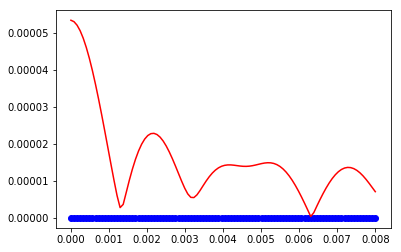

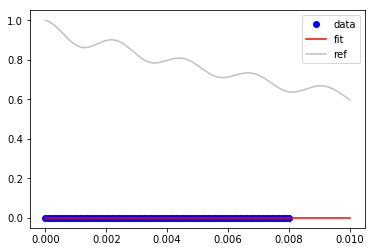

In [15]:
def func_V7(x, a,b,c,d,e,f,g):
    return np.absolute(a*np.exp(-x/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*x) + 
                       b*np.exp(-x/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*x) + 
                       c*np.exp(-x/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*x) + 
                       d*np.exp(-x/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*x) + 
                       e*np.exp(-x/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*x) +
                       f*np.exp(-x/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*x) +
                       g*np.exp(-x/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*x))

bd = (0, [1., 1., 1., 1., 1., 1., 1.]) # Bounds
popt, pcov = curve_fit(lambda t,a,b,c,d,e,f,g: np.absolute(a*np.exp(-t/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*t)+ 
                                                         b*np.exp(-t/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*t)+ 
                                                         c*np.exp(-t/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*t)+ 
                                                         d*np.exp(-t/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*t)+ 
                                                         e*np.exp(-t/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*t)+
                                                         f*np.exp(-t/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*t)+
                                                         g*np.exp(-t/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*t)),
                       t,  Sfinal, bounds=bd)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(t, func_V7(t,*popt), 'r-', label='fit2')
plt.show()

def func_V8(x, a, b, c, d, e, f, g):
    return np.absolute(a*np.exp(-x/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*x) + 
                       b*np.exp(-x/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*x) + 
                       c*np.exp(-x/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*x) + 
                       d*np.exp(-x/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*x) + 
                       e*np.exp(-x/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*x) +
                       f*np.exp(-x/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*x) +
                       g*np.exp(-x/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*x))

bd = (0, [1., 1., 1., 1., 1., 1., 1.]) # Bounds
popt, pcov = curve_fit(lambda t,a,b,c,d,e,f,g: np.absolute(a*np.exp(-t/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*t)+ 
                                                         b*np.exp(-t/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*t)+ 
                                                         c*np.exp(-t/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*t)+ 
                                                         d*np.exp(-t/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*t)+ 
                                                         e*np.exp(-t/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*t)+
                                                         f*np.exp(-t/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*t)+
                                                         g*np.exp(-t/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*t)),
                       t,  Sfinal, bounds=bd, p0=rho)
x = np.linspace(0,0.01,1001)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(x, func_V8(x,*popt), 'r-', label='fit')
plt.plot(x, func_V7(x,0.00235,0.0019500000000000001,0.00030000000000000003,0.006,0.034999999999999996,0.0044,0.95), '#C0C0C0', label='ref')
plt.legend(loc='best')
plt.show()